# Análise exploratória — churn em telecomunicações

Neste notebook, vamos explorar o arquivo `../data/telco_churn.csv` a partir da pasta `notebooks`. A análise verifica a estrutura e a qualidade dos dados, descreve a variável `Churn` e compara características de clientes que cancelaram e dos que permaneceram. Ao final, registraremos as conclusões e as decisões de limpeza do baseline.

## 1. Carregamento e estrutura dos dados

Vamos importar as bibliotecas, fixar a semente pedida e carregar o CSV usando o caminho relativo à pasta do notebook. Em seguida, mostramos as dimensões, os tipos das colunas e as cinco primeiras linhas.

In [1]:
RANDOM_STATE = 42

import math

import numpy as np

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/telco_churn.csv")

print(f"Dimensões (linhas, colunas): {df.shape}")
display(df.dtypes.rename("tipo").to_frame())
display(df.head())

Dimensões (linhas, colunas): (7043, 21)


,tipo
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Dicionário resumido das colunas

Esta tabela resume o significado das colunas para facilitar a leitura dos resultados. `customerID` identifica o cliente; `Churn` é o alvo que queremos prever.

In [2]:
column_descriptions = {
    "customerID": "Identificador único do cliente",
    "gender": "Gênero registrado do cliente",
    "SeniorCitizen": "Indica se o cliente é idoso (0 = não, 1 = sim)",
    "Partner": "Indica se o cliente tem parceiro(a)",
    "Dependents": "Indica se o cliente tem dependentes",
    "tenure": "Tempo de permanência em meses",
    "PhoneService": "Indica se o cliente tem serviço telefônico",
    "MultipleLines": "Indica se o cliente tem múltiplas linhas telefônicas",
    "InternetService": "Tipo de serviço de internet contratado",
    "OnlineSecurity": "Indica se contratou segurança online",
    "OnlineBackup": "Indica se contratou backup online",
    "DeviceProtection": "Indica se contratou proteção de dispositivo",
    "TechSupport": "Indica se contratou suporte técnico",
    "StreamingTV": "Indica se contratou streaming de TV",
    "StreamingMovies": "Indica se contratou streaming de filmes",
    "Contract": "Tipo de contrato",
    "PaperlessBilling": "Indica se usa faturamento sem papel",
    "PaymentMethod": "Método de pagamento",
    "MonthlyCharges": "Cobrança mensal em unidades monetárias",
    "TotalCharges": "Cobrança total acumulada",
    "Churn": "Indica se o cliente cancelou (Yes/No); variável alvo",
}

column_dictionary = pd.DataFrame(
    {
        "tipo": df.dtypes.astype(str),
        "descrição": pd.Series(column_descriptions),
    }
)
display(column_dictionary)

,tipo,descrição
customerID,str,Identificador único do cliente
gender,str,Gênero registrado do cliente
SeniorCitizen,int64,"Indica se o cliente é idoso (0 = não, 1 = sim)"
Partner,str,Indica se o cliente tem parceiro(a)
Dependents,str,Indica se o cliente tem dependentes
tenure,int64,Tempo de permanência em meses
PhoneService,str,Indica se o cliente tem serviço telefônico
MultipleLines,str,Indica se o cliente tem múltiplas linhas telefônicas
InternetService,str,Tipo de serviço de internet contratado
OnlineSecurity,str,Indica se contratou segurança online


## 2. Conversão de `TotalCharges`

A coluna pode conter espaços ou valores que não representam números. Vamos convertê-la com `errors="coerce"`, que transforma esses casos em valores nulos. Depois, contamos os nulos e conferimos se aparecem nas linhas em que `tenure` é zero.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

total_charges_null = df["TotalCharges"].isna()
zero_tenure = df["tenure"].eq(0)

print(f"Nulos em TotalCharges após a conversão: {total_charges_null.sum()}")
print(f"Nulos em TotalCharges com tenure == 0: {(total_charges_null & zero_tenure).sum()}")
print(f"Nulos em TotalCharges com tenure != 0: {(total_charges_null & ~zero_tenure).sum()}")
print(f"Todos os nulos coincidem com tenure == 0: {total_charges_null.equals(zero_tenure & total_charges_null)}")

Nulos em TotalCharges após a conversão: 11
Nulos em TotalCharges com tenure == 0: 11
Nulos em TotalCharges com tenure != 0: 0
Todos os nulos coincidem com tenure == 0: True


## 3. Verificações de qualidade

Linhas repetidas e identificadores repetidos podem distorcer a análise. Também vamos contar os valores ausentes em cada coluna. A conversão anterior já foi aplicada, então os nulos de `TotalCharges` aparecem nesta verificação.

In [4]:
duplicate_rows = df.duplicated().sum()
duplicate_customer_ids = df["customerID"].duplicated().sum()
missing_by_column = df.isna().sum().sort_values(ascending=False)

print(f"Linhas duplicadas: {duplicate_rows}")
print(f"customerID duplicados após a primeira ocorrência: {duplicate_customer_ids}")
print("Valores ausentes por coluna:")
display(missing_by_column.rename("valores ausentes").to_frame())

Linhas duplicadas: 0
customerID duplicados após a primeira ocorrência: 0
Valores ausentes por coluna:


,valores ausentes
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


## 4. Distribuição da variável alvo

Vamos contar os clientes em cada classe de `Churn` e calcular a participação percentual de cada uma. O gráfico facilita a comparação e ajuda a identificar o desbalanceamento entre as classes.

,contagem,percentual
Churn,,
No,5174,73.463013
Yes,1869,26.536987


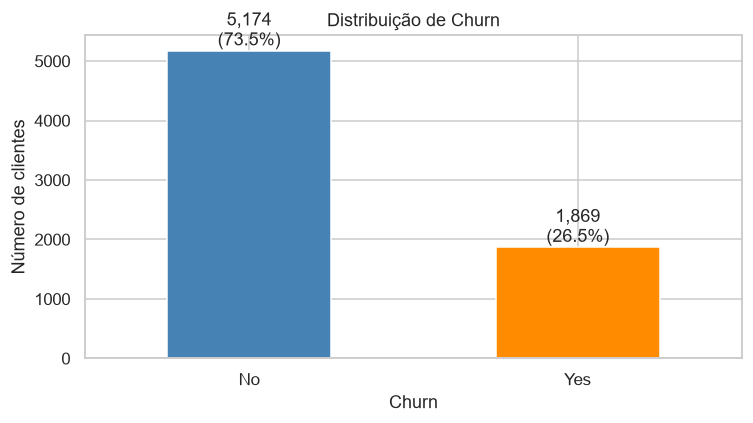

In [5]:
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"], fill_value=0)
churn_percentages = df["Churn"].value_counts(normalize=True).reindex(["No", "Yes"], fill_value=0) * 100
churn_summary = pd.DataFrame({"contagem": churn_counts, "percentual": churn_percentages})
display(churn_summary)

ax = churn_counts.plot(kind="bar", color=["steelblue", "darkorange"], figsize=(7, 4))
ax.set_title("Distribuição de Churn")
ax.set_xlabel("Churn")
ax.set_ylabel("Número de clientes")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
for bar, percentage in zip(ax.patches, churn_percentages):
    ax.annotate(
        f"{bar.get_height():,.0f}\n({percentage:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
    )
plt.tight_layout()
plt.show()

## 5. Variáveis numéricas por Churn

Os boxplots comparam `tenure`, `MonthlyCharges` e `TotalCharges` entre clientes que cancelaram e os que não cancelaram. Eles mostram a mediana, a dispersão e possíveis valores extremos. Os valores ausentes de `TotalCharges` não entram nesse gráfico.

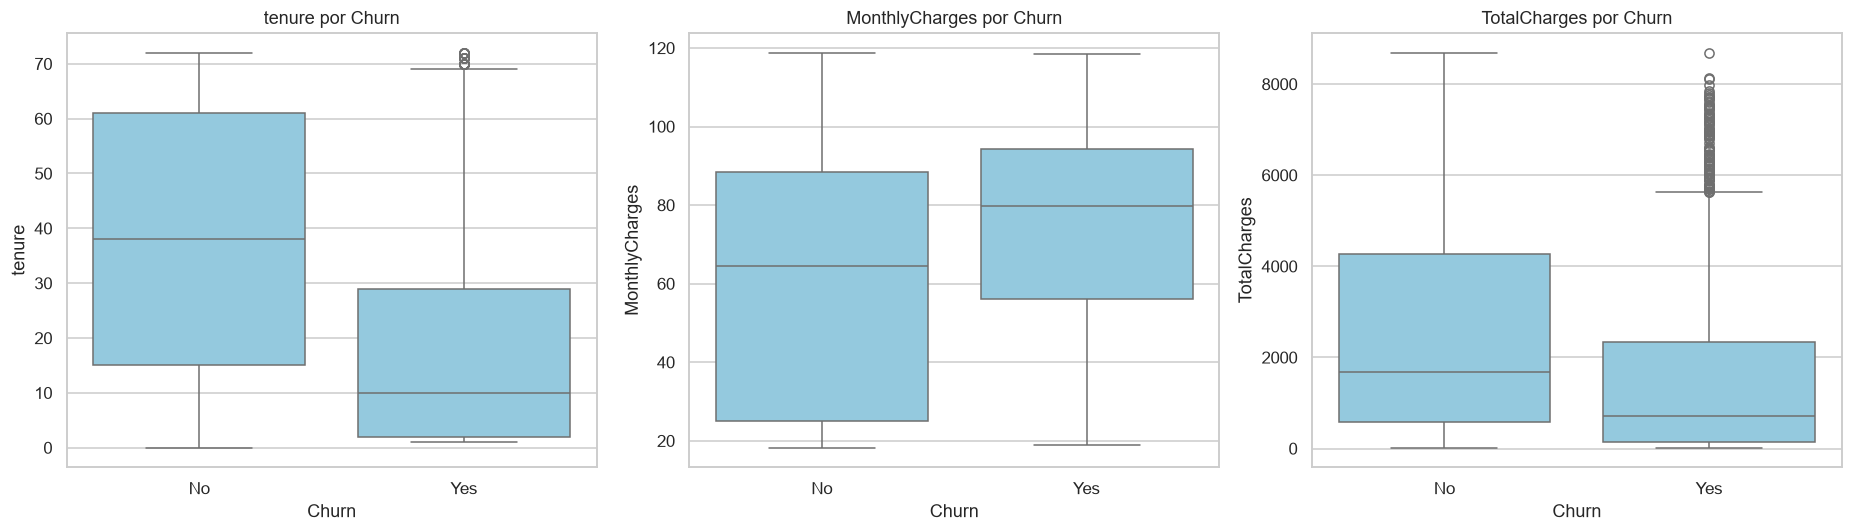

In [6]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, len(numeric_features), figsize=(17, 5))

for ax, feature in zip(axes, numeric_features):
    sns.boxplot(data=df, x="Churn", y=feature, order=["No", "Yes"], ax=ax, color="skyblue")
    ax.set_title(f"{feature} por Churn")
    ax.set_xlabel("Churn")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

## 6. Taxa de Churn por categoria

A taxa de churn de cada grupo é a proporção de clientes com `Churn = Yes`. Listamos as colunas categóricas com `df.select_dtypes(exclude="number")`. `SeniorCitizen` é armazenada como número no arquivo, mas representa uma categoria (0 ou 1), por isso também será incluída. O identificador `customerID` e o próprio alvo não são usados como características.

Colunas categóricas analisadas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'SeniorCitizen']


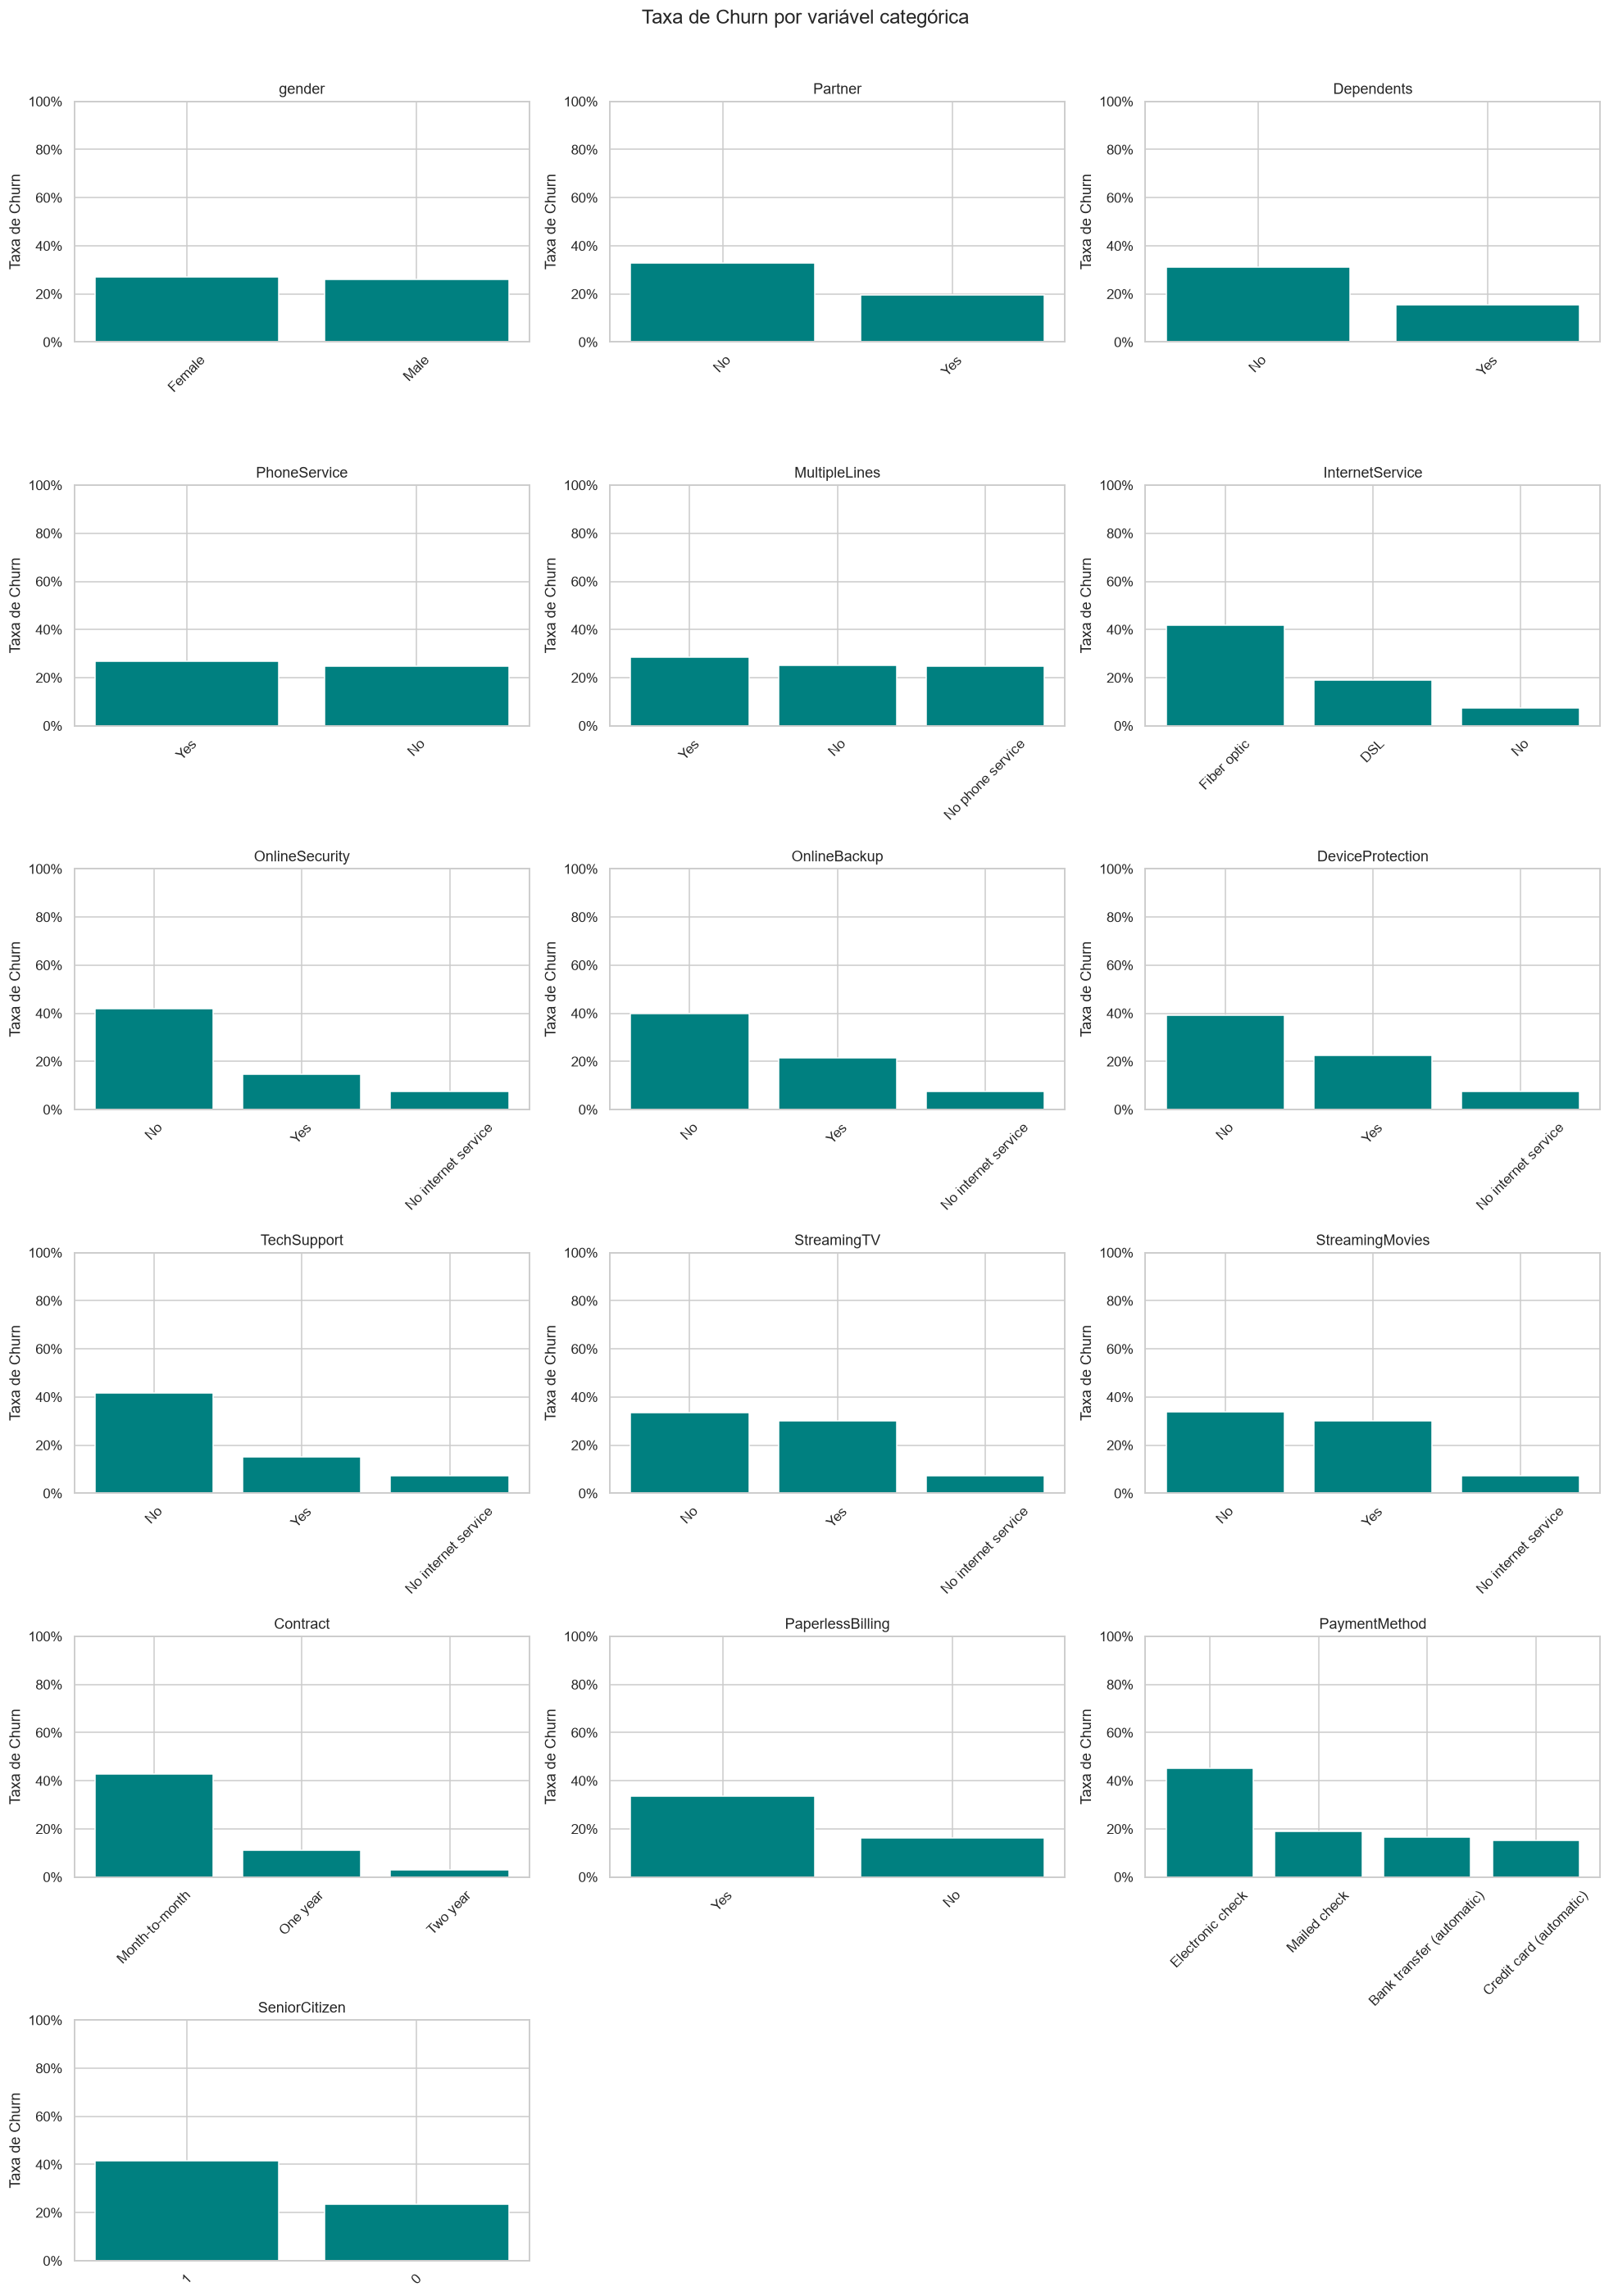

In [7]:
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()
categorical_columns = [
    column for column in categorical_columns if column not in ["customerID", "Churn"]
]
if "SeniorCitizen" in df.columns:
    categorical_columns.append("SeniorCitizen")

n_columns = 3
n_rows = math.ceil(len(categorical_columns) / n_columns)
fig, axes = plt.subplots(n_rows, n_columns, figsize=(18, n_rows * 4.2), squeeze=False)
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    plot_data = df.assign(
        _categoria=df[column].astype("string"),
        _churn=df["Churn"].eq("Yes").astype(int),
    )
    rates = (
        plot_data.groupby("_categoria", dropna=False)["_churn"]
        .mean()
        .sort_values(ascending=False)
    )
    ax.bar(rates.index.astype(str), rates.values, color="teal")
    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("Taxa de Churn")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelrotation=45)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))

for ax in axes[len(categorical_columns):]:
    ax.set_visible(False)

fig.suptitle("Taxa de Churn por variável categórica", y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

print(f"Colunas categóricas analisadas: {categorical_columns}")

## 7. Correlação entre variáveis numéricas

A matriz abaixo apresenta a correlação de Pearson entre as colunas numéricas. Para incluir o alvo, criamos uma cópia numérica com `Churn` codificado como 1 para `Yes` e 0 para `No`. Correlação descreve associação linear e, por si só, não indica causalidade.

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
SeniorCitizen,1.000000,0.016567,0.220173,0.102411,0.150889
tenure,0.016567,1.000000,0.247900,0.825880,-0.352229
MonthlyCharges,0.220173,0.247900,1.000000,0.651065,0.193356
TotalCharges,0.102411,0.825880,0.651065,1.000000,-0.199484
Churn,0.150889,-0.352229,0.193356,-0.199484,1.000000


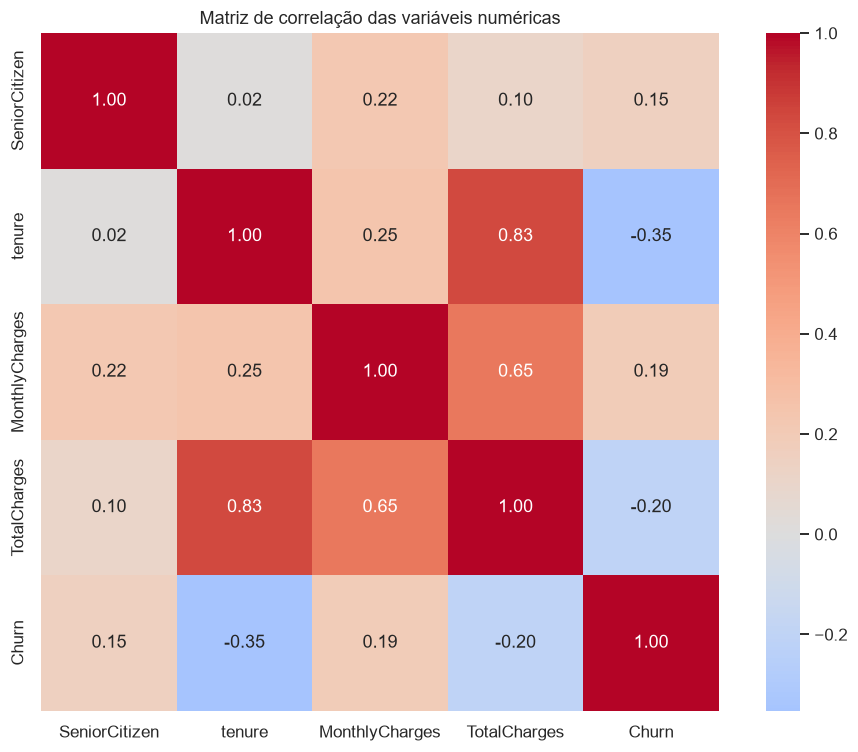

In [8]:
correlation_data = df.select_dtypes(include="number").copy()
correlation_data["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
correlation_matrix = correlation_data.corr()
display(correlation_matrix)

plt.figure(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriz de correlação das variáveis numéricas")
plt.tight_layout()
plt.show()

## 8. Conclusões e decisões de limpeza para o baseline

- **Estrutura e alvo:** a base contém 7.043 linhas e 21 colunas. São 1.869 clientes com churn (26,54%) e 5.174 sem churn (73,46%); portanto, há desbalanceamento e a avaliação deve incluir F1 e AUC-ROC, não apenas acurácia.
- **`TotalCharges`:** a conversão numérica gerou 11 nulos. Todos os 11 ocorrem em linhas com `tenure == 0`, e nenhum ocorre com `tenure` diferente de zero. Manter esses clientes e imputar os valores pela mediana dentro do pipeline, ajustando-a somente com dados de treino.
- **Duplicatas e demais ausências:** não foram encontradas linhas duplicadas nem `customerID` repetidos. Após a conversão, `TotalCharges` é a única coluna com valores ausentes.
- **`customerID`:** remover dos preditores por ser apenas um identificador.
- **Pré-processamento:** imputar variáveis numéricas pela mediana e padronizá-las; codificar as categóricas com one-hot encoding, ignorando categorias inéditas. Embora seja numérica, `SeniorCitizen` representa uma categoria e será tratada como tal no modelo.
- **Padrões descritivos:** os gráficos mostram diferenças entre as classes por contrato e serviços, além de associação entre permanência e cobrança acumulada. Na matriz, a correlação de `tenure` com `TotalCharges` é aproximadamente 0,83 e com `Churn` codificado é aproximadamente -0,35.
- **Interpretação:** diferenças e correlações são associações descritivas, não evidência de causalidade.